# Trajectory Visualization -- Module 1 + 2 + 3 Combined Output

Saves labeled panel figures of Module 2's synthesized multi-stage trajectory, with Module 3's
per-step "probability of further progression within 2 years" captioned beneath each panel.

`train_module2_poc.py` only saves a single-step training-sanity strip, and
`evaluate_trajectory.py` reduces the synthesized images straight to PSNR/SSIM/FID numbers
without saving them. This notebook is what keeps the actual images (and Module 3's estimate on
each one).

**Run this after notebooks 05, 06, AND 07 have all finished** -- it reads the Module 1 cache,
the trained Module 2 Generator checkpoint, and the trained Module 3 checkpoint + its saved LBS
thresholds, all from Drive/the current runtime's local outputs.

Module 3 estimates a probability within a fixed 2-year horizon, never an exact date. Every
synthesized (non-baseline) panel's Module 3 estimate is captioned "(synthesized image --
untested)" -- Module 3 is trained only on real photographs, so running it on Module 2's
synthesized output is mechanically possible but was not part of its training distribution.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
# Free Drive space: the training notebooks save checkpoints and caches here (several GB in total).
# Deleted or overwritten files stay in the Drive Trash and still count -- empty it if space is low.
import shutil as _shutil
try:
    _du = _shutil.disk_usage('/content/drive/MyDrive')
    print(f'Google Drive: {_du.free / 1e9:.1f} GB free of {_du.total / 1e9:.1f} GB')
    if _du.free < 10e9:
        print('⚠ Under 10 GB free on Google Drive -- model files may fail to save. Empty the Trash '
              '(drive.google.com/drive/trash) or free space before training.')
except OSError:
    pass

import getpass, os
GITHUB_TOKEN = getpass.getpass('GitHub Personal Access Token (repo scope): ')

REPO_OWNER = 'Mieka068'
REPO_NAME = 'DRProgression'
REPO_BRANCH = 'R7-GradeControl-Eval'  # <-- round 7; 'R6-ShapeFix-Controls' = round 6, 'R5-Round3Baseline-Fixes' = round 5, 'AllModuleEdits-PreFinals' = rounds 3/4, 'mod-2-NonLongIntegration' = the earlier runs
REPO_CODE_SUBDIR = 'M2-DRProgression-VerM-module1-fgadr-poc'

DRIVE_DATA_DIR = '/content/drive/MyDrive/Thesis_Datasets'
assert os.path.isdir(DRIVE_DATA_DIR), f"Not found: {DRIVE_DATA_DIR}"

# Which Module 1 models the pipeline uses -- set the SAME value in notebooks 04_05 and 06-10:
#   'drgnet' -- notebook 11's DRG-Net replication checkpoints (module1_runs/drgnet_replication/)
#   'poc'    -- notebooks 02/03's original POC checkpoints (module1_runs/)
# Everything built from Module 1's outputs (Module 1 caches, Module 2 runs, figures) gets a
# '_drgnet' suffix for 'drgnet', so the two pipelines never overwrite each other's results.
MODULE1_SOURCE = 'drgnet_combined'
assert MODULE1_SOURCE in ('drgnet_combined', 'drgnet', 'poc'), MODULE1_SOURCE
# New Drive folders for this branch's runs: every Module 1 cache / Module 2 / Module 3 folder below
# gets RUN_SUFFIX, so the mod-2-NonLongIntegration results stay untouched for before/after
# comparison. '' = read/write the earlier folders again.
RUN_SUFFIX = '_prefinals'
RUN_TAG = {'drgnet_combined': '_drgnet_comb', 'drgnet': '_drgnet', 'poc': ''}[MODULE1_SOURCE] + RUN_SUFFIX
# Round 4: every Module 1 cache / Module 2 / Module 3 folder ALSO gets ROUND_TAG, so round 3's results
# (no ROUND_TAG) stay untouched for before/after comparison -- the SAME value in notebooks 04_05 and 06-10.
# Model folders (notebook 11) and the laterality file keep RUN_SUFFIX only. '' = round 3's folders.
# Round 5 (branch R5-Round3Baseline-Fixes): round 3's Module 2 settings (128 px, no grader loss, round 3's
# best-epoch rule) + the data fixes (text-safe retina crop, SIFT failures dropped). '_r4' = round 4's folders.
# Round 6 (branch R6-ShapeFix-Controls): reads round 5's Module 1 caches, laterality file, pretrained Generator
# and Module 3 as they are (INPUT_ROUND_TAG); writes figures/outputs to new '_r6' folders (ROUND_TAG).
# Round 7 (branch R7-GradeControl-Eval): same inputs (round 5's), figures/outputs to new '_r7' folders.
ROUND_TAG = '_r7'
INPUT_ROUND_TAG = '_r5'
BASE_RUN_TAG = RUN_TAG
INPUT_RUN_TAG = BASE_RUN_TAG + INPUT_ROUND_TAG
RUN_TAG = BASE_RUN_TAG + ROUND_TAG
# Image preprocessing for every script this notebook runs (fundus_preprocess.py), the same in 04_05-10:
#   DRP_RETINA_CROP '1' = crop to the retina and pad to square before resizing (Tianjin's 3:2 and LongDR's
#     2000x1312 photos were squashed into ovals); '0' = round 3's plain resize.
#   DRP_LONGDR_FOLDER 'FundusImagesColor' = LongDR's raw colour photos. Round 3 used FundusImagesNormalized,
#     on which the lesion segmenters (trained on raw photos) marked 10-30 % of a NORMAL retina as lesion
#     (LBS 0.1-0.34 at grade 0, vs ~0.001 on Tianjin/FIRE) -- 559 of the 917 Module 2 pairs.
os.environ['DRP_RETINA_CROP'] = '1'
os.environ['DRP_LONGDR_FOLDER'] = 'FundusImagesColor'
# Module 2 resolution -- the SAME value in notebooks 06, 08, 09 and 10 (item 4.3; the scripts stop
# with an error on a mismatch).
# Round 4: 'auto' = the size notebook 04_05's grader-resolution check recommends (its
# grader_resolution_check.json in this round's Module 1 cache folder): 256 px when the grader reads real
# Tianjin images clearly better at 256 than at 128 px (kappa +0.05 or more), else 128 (~4x faster). Set a
# number (128 / 256) to override. Run 04_05 to the end BEFORE 09 / 06, so every notebook gets the same size.
MODULE2_IMAGE_SIZE = 128  # round 5: 128 px (round 3) until the outputs are clean; 'auto' = notebook 04_05's recommendation (256 in round 4)
MODULE1_RUNS = os.path.join(DRIVE_DATA_DIR, 'module1_runs', *(['drgnet_replication'] if MODULE1_SOURCE != 'poc' else []))
# Notebook 11 on this branch writes its models to drgnet_replication<RUN_SUFFIX>/ (tiled evaluation,
# 200 segmentation epochs, optional EyePACS grader); use those once they exist.
if MODULE1_SOURCE != 'poc' and os.path.isdir(os.path.join(MODULE1_RUNS + RUN_SUFFIX, 'segmentation')):
    MODULE1_RUNS += RUN_SUFFIX
elif MODULE1_SOURCE != 'poc' and RUN_SUFFIX:
    print(f'\u26a0 {MODULE1_RUNS + RUN_SUFFIX} not found -- using the earlier Module 1 models in {MODULE1_RUNS}. '
          'Run notebook 11 on this branch first for the re-trained ones.')
# Lesion segmenters: <MODULE1_RUNS>/segmentation/<SEG_MODEL_PREFIX><lesion>/model_2.pth.tar --
# FGADR + DDR combined (notebook 11) or FGADR only. The classifier is FGADR's either way.
SEG_MODEL_PREFIX = 'comb_models_' if MODULE1_SOURCE == 'drgnet_combined' else 'models_FGADR_NO_TATL_'
# Round 4: notebook 11's fine-tuned combined segmenters (comb_ft_models_*) once all four exist.
if MODULE1_SOURCE == 'drgnet_combined':
    if all(os.path.isfile(os.path.join(MODULE1_RUNS, 'segmentation', f'comb_ft_models_{_l}', 'model_2.pth.tar'))
           for _l in ('ex', 'he', 'ma', 'se')):
        SEG_MODEL_PREFIX = 'comb_ft_models_'
    elif ROUND_TAG:
        print('\u26a0 Fine-tuned segmenters (comb_ft_models_*) not all on Drive yet -- using the 200-epoch '
              'comb_models_*. Run notebook 11 (RUN["comb_seg_ft"]) first for round 4.')
print('Lesion segmenters:', SEG_MODEL_PREFIX + '<lesion>')
MODULE1_CACHE_DIR = os.path.join(DRIVE_DATA_DIR, 'module1_cache' + INPUT_RUN_TAG)  # round 5's caches (read only)
os.makedirs(MODULE1_CACHE_DIR, exist_ok=True)
print('Module 1 source:', MODULE1_SOURCE, '| models:', MODULE1_RUNS, '| caches:', MODULE1_CACHE_DIR)
if MODULE2_IMAGE_SIZE == 'auto':
    import json as _json
    _res_json = os.path.join(MODULE1_CACHE_DIR, 'grader_resolution_check.json')
    if os.path.isfile(_res_json):
        _res = _json.load(open(_res_json))
        if _res.get('recommended_image_size'):
            MODULE2_IMAGE_SIZE = int(_res['recommended_image_size'])
        else:  # a check file written before the recommended_image_size field
            _gain = max((_res.get('kappa_gain_high_vs_low') or {0: 0}).values())
            MODULE2_IMAGE_SIZE = max(_res['sizes']) if _gain >= 0.05 else min(_res['sizes'])
        print(f'MODULE2_IMAGE_SIZE = {MODULE2_IMAGE_SIZE} (auto, from {_res_json}: {_res.get("recommendation")})')
    else:
        MODULE2_IMAGE_SIZE = 256
        print(f'\u26a0 MODULE2_IMAGE_SIZE = 256 (auto fallback): {_res_json} not found -- run notebook 04_05 to the end '
              'first, or set MODULE2_IMAGE_SIZE by hand. Every Module 2 notebook must use the same size.')
TIANJIN_CACHE = os.path.join(MODULE1_CACHE_DIR, 'module1_outputs_tianjin.pt')
assert os.path.isfile(TIANJIN_CACHE), f"Not found: {TIANJIN_CACHE} -- run notebook 04_05 first (same MODULE1_SOURCE)."

Mounted at /content/drive
Google Drive: 151.8 GB free of 214.7 GB
GitHub Personal Access Token (repo scope): ··········
Lesion segmenters: comb_ft_models_<lesion>
Module 1 source: drgnet_combined | models: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals | caches: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r5


In [2]:
# Unzip Tianjin locally (same convention as notebooks 05/06/07).
import glob

os.makedirs('/content/data', exist_ok=True)
%cd /content/data
!unzip -q -n "$DRIVE_DATA_DIR/retinal-dr-longitudinal.zip" -d _tianjin_extract_raw

_manifest_candidates = glob.glob('/content/data/_tianjin_extract_raw/**/corrected_manifest.csv', recursive=True)
assert _manifest_candidates, 'No corrected_manifest.csv found -- see notebook 05 for troubleshooting.'
_tianjin_root = os.path.dirname(_manifest_candidates[0])
TIANJIN_DIR = '/content/data/retinal-dr-longitudinal'
if _tianjin_root != TIANJIN_DIR and not os.path.exists(TIANJIN_DIR):
    os.symlink(_tianjin_root, TIANJIN_DIR)

# Same laterality-resolution fetch-or-compute as notebooks 05/06/07 -- required by
# tianjin_dataset.py / module3/dataset.py.
# This branch re-tuned module1/resolve_eye_laterality.py (item 7.1), so it gets its own copy
# (module1_cache<RUN_SUFFIX>/); the settings come from notebook 11's EyePACS validation when it exists.
# _v2: the first file on this branch used the EyePACS validation's convention at only ~61 % accuracy
# (EyePACS mixes mirrored and non-mirrored images) -> 20.6 % of patients had both eyes labelled alike.
# Round 5: its own copy in this round's cache folder (the text-safe crop changes the field of view the
# optic-disc position is measured in); rounds 3/4 ('' / '_r4') share module1_cache<RUN_SUFFIX>/.
_LAT_DIR = 'module1_cache' + (RUN_SUFFIX if INPUT_ROUND_TAG in ('', '_r4') else INPUT_RUN_TAG)  # round 6: round 5's file
LATERALITY_DRIVE_PATH = os.path.join(DRIVE_DATA_DIR, _LAT_DIR, 'laterality_resolved_v2.csv')
os.makedirs(os.path.dirname(LATERALITY_DRIVE_PATH), exist_ok=True)
LATERALITY_LOCAL_PATH = os.path.join(TIANJIN_DIR, 'laterality_resolved.csv')
assert os.path.isfile(LATERALITY_DRIVE_PATH), (
    f"Not found: {LATERALITY_DRIVE_PATH} -- run notebook 04_05 (or 06/07) on this branch first (it computes and persists this)."
)
import shutil
shutil.copy(LATERALITY_DRIVE_PATH, LATERALITY_LOCAL_PATH)
print('Tianjin manifest found:', os.path.isfile(os.path.join(TIANJIN_DIR, 'corrected_manifest.csv')))

/content/data
Tianjin manifest found: True


In [3]:
# Clone this repo. Skips cleanly if already cloned in this runtime.
%cd /content
if not os.path.isdir(f'/content/{REPO_NAME}'):
    !git clone --branch {REPO_BRANCH} https://{GITHUB_TOKEN}@github.com/{REPO_OWNER}/{REPO_NAME}.git {REPO_NAME}

REPO_CODE_DIR = f'/content/{REPO_NAME}/{REPO_CODE_SUBDIR}'
assert os.path.isdir(REPO_CODE_DIR), f"Not found: {REPO_CODE_DIR} -- check REPO_BRANCH/REPO_CODE_SUBDIR above"

%cd {REPO_CODE_DIR}
!pip install -q pandas openpyxl segmentation-models-pytorch matplotlib

/content
Cloning into 'DRProgression'...
remote: Enumerating objects: 1253, done.
remote: Counting objects: 100% (419/419), done.
remote: Compressing objects: 100% (260/260), done.
remote: Total 1253 (delta 263), reused 227 (delta 159), pack-reused 834 (from 1)
Receiving objects: 100% (1253/1253), 44.77 MiB | 10.31 MiB/s, done.
Resolving deltas: 100% (748/748), done.
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc


In [4]:
# Locate the Module 1 classifier + EX/MA (+ HE/SE if trained) checkpoints, same discovery
# logic as notebooks 04/05/06.
import glob

SEG_DIR   = os.path.join(MODULE1_RUNS, 'segmentation')
# Module 1 grader: 'eyepacs' (default) = DRG-Net's classifier trained on EyePACS (notebook 11, training
# capped at 3000 images/grade); 'fgadr' = the FGADR grader. Notebook 04_05's grader-comparison cell scores
# both on Tianjin's clinical grades -- set the one it recommends in notebooks 04_05, 06, 08, 09 and 10.
# With 'eyepacs' and no EyePACS grader on Drive, the FGADR one is used.
CLASSIFIER_RUN = 'eyepacs'
if not glob.glob(os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves', '*.pt')):
    print(f'\u26a0 No {CLASSIFIER_RUN} grader in {MODULE1_RUNS} yet -- using the FGADR one')
    CLASSIFIER_RUN = 'fgadr'
CLS_SAVES = os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves')
# Classifier input normalisation must match its training config (eyepacs_poc.yaml differs).
CLS_NORM_ARGS = ' --classifier-norm eyepacs' if CLASSIFIER_RUN == 'eyepacs' else ''

# EyePACS: best_validation_weights.pt (picked on the Kaggle public test, kept apart from its test set);
# FGADR: final_weights.pt (its "validation" set IS its test set, so the best-validation pick is optimistic).
_pref  = (['best_validation_weights.pt', 'final_weights.pt'] if CLASSIFIER_RUN == 'eyepacs'
          else ['final_weights.pt', 'best_validation_weights.pt'])
_cands = [os.path.join(CLS_SAVES, n) for n in _pref] + sorted(
    glob.glob(os.path.join(CLS_SAVES, '*.pt')), key=os.path.getmtime, reverse=True)
CLS_CKPT = next((p for p in _cands if os.path.isfile(p)), None)
assert CLS_CKPT, f"No classifier .pt in {CLS_SAVES} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"

EX_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'ex', 'model_2.pth.tar')
MA_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'ma', 'model_2.pth.tar')
for _p in (CLS_CKPT, EX_CKPT, MA_CKPT):
    assert os.path.isfile(_p), f"missing checkpoint: {_p} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"

HE_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'he', 'model_2.pth.tar')
SE_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'se', 'model_2.pth.tar')
_extra_seg_args = ''
if os.path.isfile(HE_CKPT):
    _extra_seg_args += f' --seg-checkpoint HE={HE_CKPT}'
if os.path.isfile(SE_CKPT):
    _extra_seg_args += f' --seg-checkpoint SE={SE_CKPT}'
print('classifier :', CLS_CKPT)
print('EX seg     :', EX_CKPT)
print('MA seg     :', MA_CKPT)
print('HE seg     :', HE_CKPT if os.path.isfile(HE_CKPT) else 'not trained yet')
print('SE seg     :', SE_CKPT if os.path.isfile(SE_CKPT) else 'not trained yet')

# Module 2 + Module 3 checkpoints, from notebooks 06 and 07's local runtime outputs (or copy
# them here from Drive first if this is a fresh runtime from those notebooks).
# Module 2 Generator from notebook 06 (same MODULE1_SOURCE): Drive copy first, then this runtime;
# the EyePACS-pretrained run before the random-init ablation.
# best-G.ckpt (best epoch on held-out pairs) before final-G.ckpt (last epoch).
# Rounds 6/7: which Generator to use -- 'finetuned' = notebook 06's best-G.ckpt from this round (round 7); 'round6' =
# round 6's fine-tuned best-G.ckpt (sharper, looks like an eye; round 7's grader loss blurred it) run through round 7's
# colour match; 'pretrained' = notebook 09's EyePACS-pretrained Generator from round 5 (no longitudinal fine-tuning).
# Each choice writes to its own output folder.
GENERATOR = 'round6'
assert GENERATOR in ('finetuned', 'round6', 'pretrained'), GENERATOR
ROUND6_CKPT = os.path.join(DRIVE_DATA_DIR, 'module2_runs', 'models_poc_tianjin_from_nonlong' + BASE_RUN_TAG + '_r6', 'best-G.ckpt')
FOV_MASK = True   # round 6: black out every synthesized step outside the baseline's retina circle
FOV_ARG = ' --fov-mask' if FOV_MASK else ''  # not inline: a Python expression inside !python may not expand
# Round 7: the same cascade clean-up as notebook 06 (use the same values): every step's colours matched to the real
# baseline (COLOR_MATCH; round 6's grey drift). FOV_ERODE / FOV_FEATHER pull the retina mask in / fade its edge -- 0, 0 =
# the baseline's full circle, as in round 6 (4, 3 made the eye ~12 % narrower with a dimmed rim; 2, 0 = 97 % size).
# CASCADE_MODE 'direct' = every stage from the real baseline instead of the previous step (comparison only).
FOV_ERODE, FOV_FEATHER, COLOR_MATCH = 0, 0, True
CASCADE_MODE = 'cascade'
CASCADE_ARGS = ((f' --fov-erode {FOV_ERODE} --fov-feather {FOV_FEATHER}' if FOV_MASK else '')
                + (' --color-match' if COLOR_MATCH else '')
                + (' --cascade-mode direct' if CASCADE_MODE == 'direct' else ''))
OUT_SUFFIX = RUN_TAG + {'finetuned': '', 'round6': '_round6G', 'pretrained': '_pretrained'}[GENERATOR] + ('_direct' if CASCADE_MODE == 'direct' else '')
_gen_cands = [os.path.join(base, run + RUN_TAG, ckpt)
              for run in ('models_poc_tianjin_from_nonlong', 'models_poc_tianjin')
              for base in (os.path.join(DRIVE_DATA_DIR, 'module2_runs'), f'{REPO_CODE_DIR}/DRForestGAN-v2/stargan')
              for ckpt in ('best-G.ckpt', 'final-G.ckpt')]
# This round's fine-tuning run (its poc_results.json lists the patients to leave out, for either GENERATOR).
FINETUNED_CKPT = next((p for p in _gen_cands if os.path.isfile(p)), _gen_cands[0])
GENERATOR_CKPT = {'finetuned': FINETUNED_CKPT, 'round6': ROUND6_CKPT,
                  'pretrained': os.path.join(DRIVE_DATA_DIR, 'module2_runs', 'nonlong_pretrain' + INPUT_RUN_TAG, 'final-G.ckpt')}[GENERATOR]
print('generator :', GENERATOR_CKPT, f'({GENERATOR})')
# Module 3 from notebook 07 (same MODULE1_SOURCE): its Drive copy first, then this runtime.
# Round 6: notebook 07 isn't re-run -- round 5's Module 3 (INPUT_RUN_TAG).
_m3_dir = next((d for d in (os.path.join(DRIVE_DATA_DIR, 'module3_runs', 'module3_runs_poc' + INPUT_RUN_TAG),
                            f'{REPO_CODE_DIR}/module3/module3_runs_poc')
                if os.path.isfile(os.path.join(d, 'final-model.ckpt'))),
               os.path.join(DRIVE_DATA_DIR, 'module3_runs', 'module3_runs_poc' + INPUT_RUN_TAG))
MODULE3_CKPT = next((os.path.join(_m3_dir, c) for c in ('best-model.ckpt', 'final-model.ckpt')
                     if os.path.isfile(os.path.join(_m3_dir, c))), os.path.join(_m3_dir, 'final-model.ckpt'))
MODULE3_RESULTS_JSON = os.path.join(_m3_dir, 'poc_results.json')
print('module 3  :', MODULE3_CKPT)
for _p in (GENERATOR_CKPT, MODULE3_CKPT, MODULE3_RESULTS_JSON):
    assert os.path.isfile(_p), (
        f"Not found: {_p} -- run notebook 06 (Module 2) and notebook 07 (Module 3) first, "
        "with the same MODULE1_SOURCE."
    )
# Figures go to Drive (the runtime disk is wiped when the session ends).
TRAJ_FIG_DIR = os.path.join(DRIVE_DATA_DIR, 'module2_runs', 'trajectory_figures' + OUT_SUFFIX)
os.makedirs(TRAJ_FIG_DIR, exist_ok=True)

classifier : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/classification/eyepacs/saves/best_validation_weights.pt
EX seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_ex/model_2.pth.tar
MA seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_ma/model_2.pth.tar
HE seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_he/model_2.pth.tar
SE seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_se/model_2.pth.tar
generator : /content/drive/MyDrive/Thesis_Datasets/module2_runs/models_poc_tianjin_from_nonlong_drgnet_comb_prefinals_r6/best-G.ckpt (round6)
module 3  : /content/drive/MyDrive/Thesis_Datasets/module3_runs/module3_runs_poc_drgnet_comb_prefinals_r5/best-model.ckpt


In [5]:
# END_STAGE = None stops each patient at their real follow-up grade (original behaviour);
# END_STAGE = 4 cascades every patient all the way to PDR. (Any image, not just Tianjin:
# notebook 10.)
END_STAGE = None
_end_stage_arg = f' --end-stage {END_STAGE}' if END_STAGE is not None else ''
# Round 4: only patients the Generator never trained on (its poc_results.json lists the training patients)
# and eyes starting at >= mild NPDR (MIN_BASELINE_GRADE = 1, the thesis scope; 0 = all).
MIN_BASELINE_GRADE = 1
# Training patients to leave out: round 6's own run for GENERATOR = 'round6', else this round's (same split either way)
_poc = os.path.join(os.path.dirname(ROUND6_CKPT if GENERATOR == 'round6' else FINETUNED_CKPT), 'poc_results.json')
_end_stage_arg += f' --min-baseline-grade {MIN_BASELINE_GRADE}' + (f' --exclude-train-from "{_poc}"' if os.path.isfile(_poc) else '')
if not os.path.isfile(_poc):
    print(f'\u26a0 {_poc} not found -- the figures may show patients the Generator trained on')
%cd {REPO_CODE_DIR}
!python visualize_trajectory.py --image-size {MODULE2_IMAGE_SIZE} \
    --tianjin-dir "{TIANJIN_DIR}" \
    --tianjin-module1-cache "{TIANJIN_CACHE}" \
    --generator-checkpoint "{GENERATOR_CKPT}" \
    --classifier-checkpoint "{CLS_CKPT}"{CLS_NORM_ARGS} \
    --seg-checkpoint EX="{EX_CKPT}" --seg-checkpoint MA="{MA_CKPT}"{_extra_seg_args} \
    --module3-checkpoint "{MODULE3_CKPT}" \
    --module3-thresholds-json "{MODULE3_RESULTS_JSON}" \
    --num-patients 4{_end_stage_arg}{FOV_ARG}{CASCADE_ARGS} \
    --out-dir "{TRAJ_FIG_DIR}"

/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
Classifier normalisation: eyepacs mean=[0.425753653049469, 0.29737451672554016, 0.21293757855892181] std=[0.27670302987098694, 0.20240527391433716, 0.1686241775751114]
Lesion segmentation: tiled (retina 1280 px, 512 px tiles, stride 384) | retina crop: on
Device: cuda

[1/4] Loading Tianjin survival dataset (source of real progression pairs)...
✓ Loaded Module 1 cache: 1234 images (/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r5/module1_outputs_tianjin.pt)
  Total eye-pairs in corrected_manifest.csv: 1115
  Baseline sheet 'Baseline': patient_id <- 'ID', OS <- 'OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', OD <- 'OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderat

4 figure(s) saved:
  /content/drive/MyDrive/Thesis_Datasets/module2_runs/trajectory_figures_drgnet_comb_prefinals_r7_round6G/patient_620_row13.png


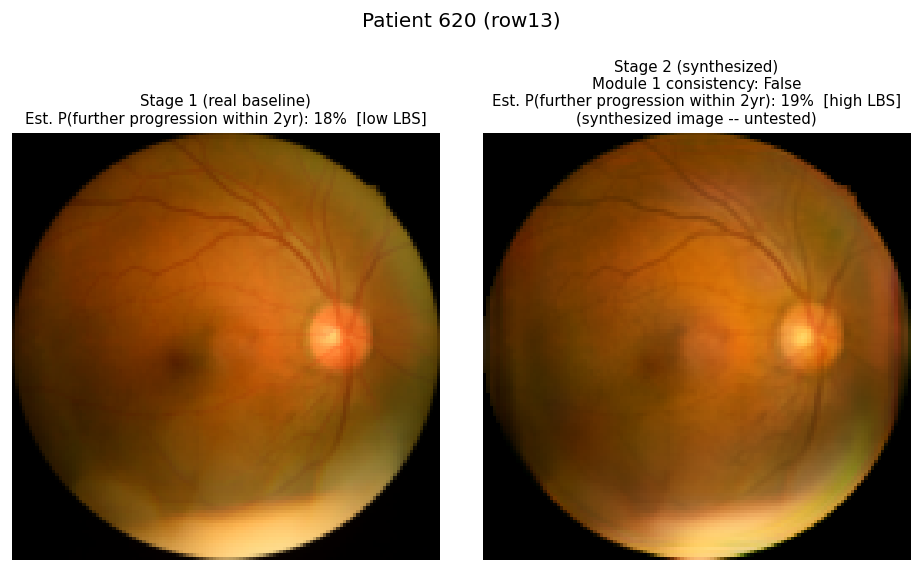

  /content/drive/MyDrive/Thesis_Datasets/module2_runs/trajectory_figures_drgnet_comb_prefinals_r7_round6G/patient_822_OD.png


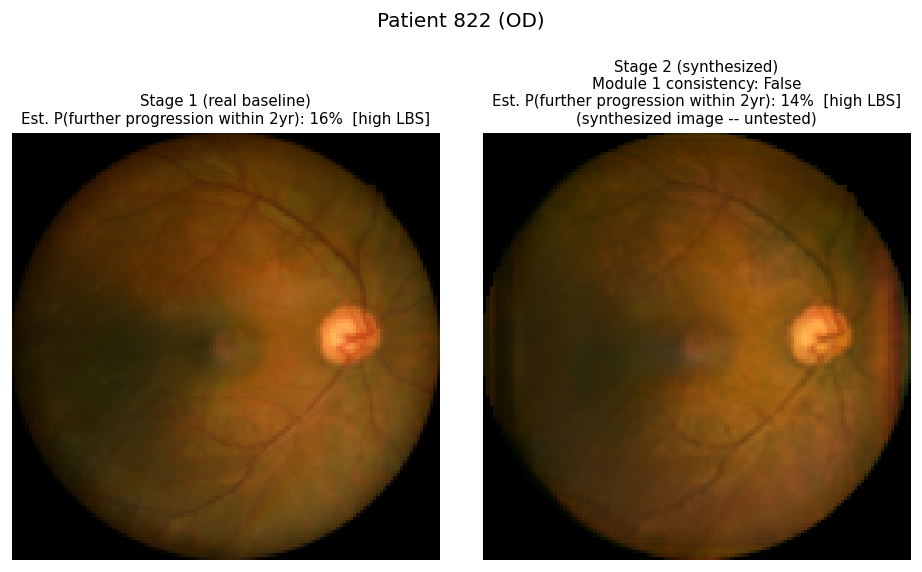

  /content/drive/MyDrive/Thesis_Datasets/module2_runs/trajectory_figures_drgnet_comb_prefinals_r7_round6G/patient_830_row25.png


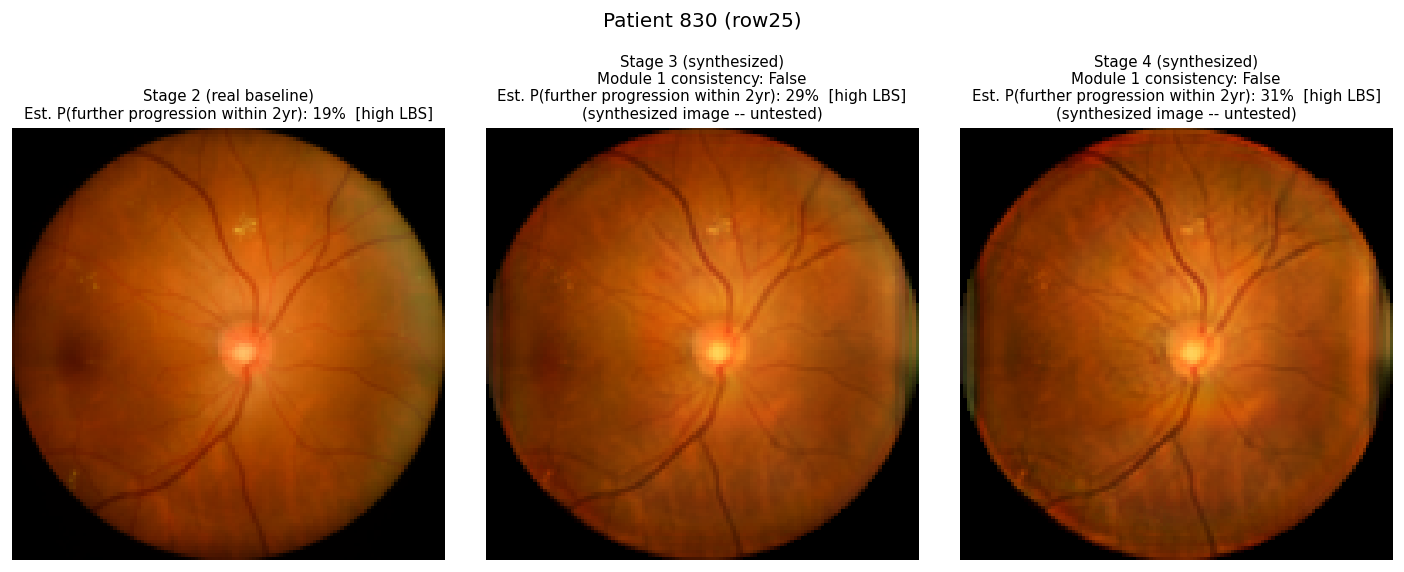

  /content/drive/MyDrive/Thesis_Datasets/module2_runs/trajectory_figures_drgnet_comb_prefinals_r7_round6G/patient_830_row26.png


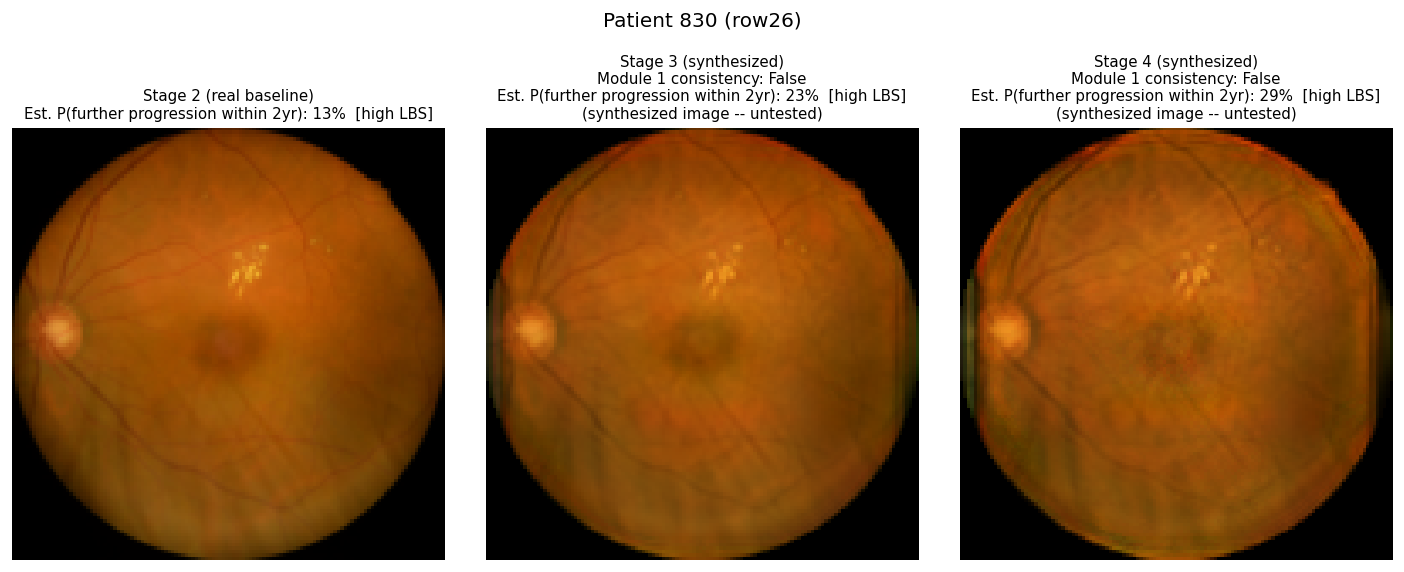

In [6]:
from IPython.display import Image as IPImage, display
import glob

figures = sorted(glob.glob(f'{TRAJ_FIG_DIR}/patient_*.png'))
print(f'{len(figures)} figure(s) saved:')
for fig_path in figures:
    print(' ', fig_path)
    display(IPImage(fig_path))

## Caveats

- These figures show real progression pairs from Tianjin only (patients whose real follow-up
  grade is higher than their real baseline grade) -- the cascade is only defined for
  progression, not regression or no-change.
- Module 3's caption is "estimated probability of further progression within 2 years," never
  a specific date -- that is the only horizon the model has real training signal for.
- Every synthesized (non-baseline) panel's Module 3 estimate is marked "(synthesized image --
  untested)": Module 3 is trained only on real baseline photographs, and running it on a
  Module-2-synthesized image is mechanically possible but was not part of its training
  distribution.
- Module 1's "consistency" flag on each synthesized panel means the re-graded synthesized
  image matches the intended target stage -- a False here could mean the generator produced
  something implausible, or that Module 1's own grader is unreliable on synthesized
  (out-of-distribution) images, or both.

## Before closing the runtime

Files written to Drive upload in the background. Run this last cell and wait for the ✓ before
disconnecting or deleting the runtime -- otherwise large files written at the end (model weights,
caches) can be lost.

In [7]:
from google.colab import drive
drive.flush_and_unmount()
print('✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.')

✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.
